# 04 · Les postes qui peinent à recruter

Le plan prévoyait un modèle du salaire. Le service public ne publie pas de salaire dans ses offres : cette étape prend
une cible de repli qui dit, elle aussi, quelque chose du marché. Quand un employeur **remet en ligne le même poste**
quelques semaines ou mois plus tard, c'est en général qu'il n'a pas trouvé. On appelle donc **republiée** une annonce
dont le poste (même organisme, même métier, même intitulé, même département) revient au moins une fois entre 7 et 180
jours après. Sous 7 jours, c'est plutôt un doublon ou une correction (qui ne masque pas une vraie relance ensuite) ;
au-delà de 6 mois, plutôt un nouveau recrutement.

Questions :
1. Quels postes sont le plus souvent republiés, et cette part évolue-t-elle ?
2. Peut-on prévoir, le jour de la publication, qu'une annonce sera republiée ?
3. Quelles caractéristiques pèsent dans cette prévision (SHAP) ?
4. Certaines compétences demandées vont-elles avec plus de republications ?

Limites de la cible : un employeur qui recrute plusieurs fois le même poste pour des postes différents (un CHU qui
embauche des infirmiers de nuit toute l'année) compte comme une republication ; un poste pourvu par une autre voie
(mutation, concours) sans nouvelle annonce n'en compte pas. C'est un indicateur de tension, pas une mesure exacte. Les
annonces sans métier ou sans département sont écartées, faute de pouvoir identifier le poste.

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score

from offres import competences as comp
from offres import donnees
from offres import graphiques as g
from offres import recrutement as rec

g.style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(80)
POURCENT = mtick.FuncFormatter(lambda v, _: f"{v:.0%}".replace("%", " %"))
offres = donnees.offres_service_public()
a = rec.republications(offres).with_columns(annee=pl.col("date_publication").dt.year())
print(f"{a.height:,} annonces publiées du {a['date_publication'].min()} au {a['date_publication'].max()} "
      f"(les plus récentes sont écartées : on ne sait pas encore si elles reviendront)")
print(f"Republiées : {a['republiee'].mean():.1%}")
a.group_by("annee").agg(annonces=pl.len(), republiees=pl.col("republiee").mean()).sort("annee")

1,391,813 annonces publiées du 2022-01-02 au 2026-03-31 (les plus récentes sont écartées : on ne sait pas encore si elles reviendront)
Republiées : 14.3%


annee,annonces,republiees
i32,u32,f64
2022,292523,0.127238
2023,329588,0.126673
2024,341765,0.147359
2025,342300,0.162287
2026,85637,0.164835


## 1. Qui republie ?

shape: (4, 3)
┌────────────────────────────────┬──────────┬────────────┐
│ versant                        ┆ annonces ┆ republiees │
│ ---                            ┆ ---      ┆ ---        │
│ str                            ┆ u32      ┆ f64        │
╞════════════════════════════════╪══════════╪════════════╡
│ null                           ┆ 6181     ┆ 0.254166   │
│ Fonction Publique Territoriale ┆ 858190   ┆ 0.158239   │
│ Fonction Publique Hospitalière ┆ 84262    ┆ 0.122333   │
│ Fonction Publique de l'Etat    ┆ 443180   ┆ 0.115802   │
└────────────────────────────────┴──────────┴────────────┘
shape: (5, 3)
┌───────────┬──────────┬────────────┐
│ categorie ┆ annonces ┆ republiees │
│ ---       ┆ ---      ┆ ---        │
│ str       ┆ u32      ┆ f64        │
╞═══════════╪══════════╪════════════╡
│ C         ┆ 547248   ┆ 0.179714   │
│ B         ┆ 344405   ┆ 0.129284   │
│ A         ┆ 449744   ┆ 0.11595    │
│ A+        ┆ 33541    ┆ 0.084792   │
│ null      ┆ 16875    ┆ 0.067141   │
└─

230 métiers d'au moins 1 000 annonces


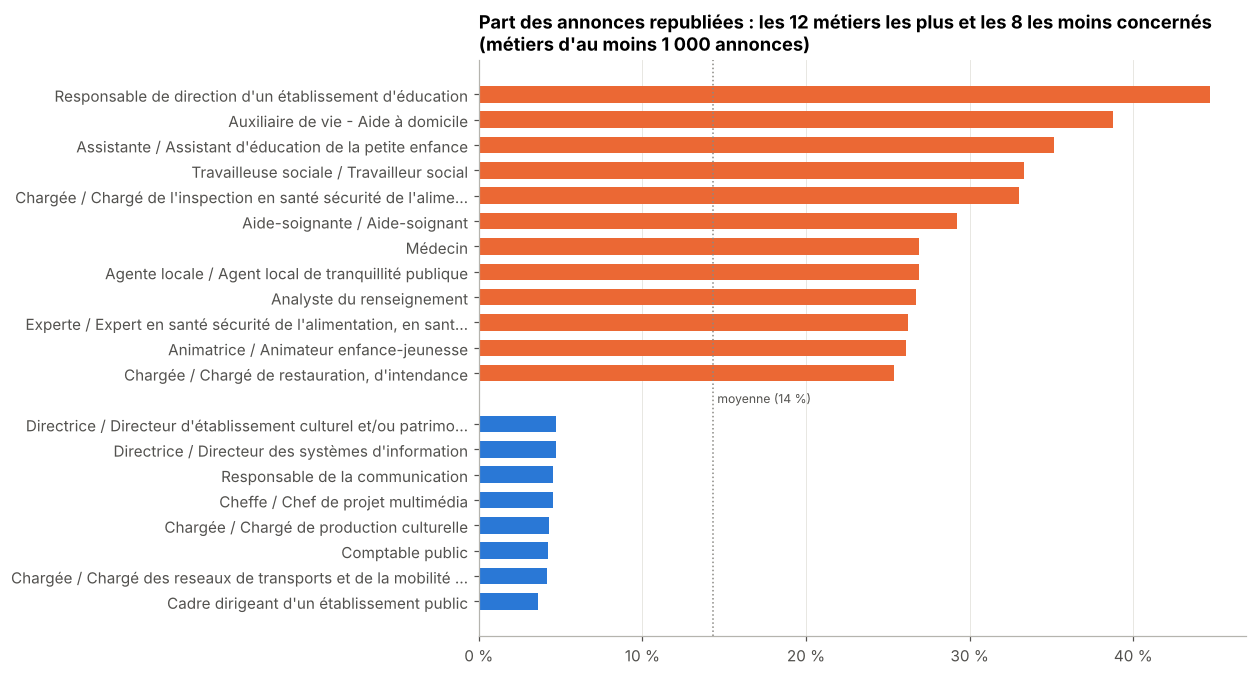

In [2]:
par = lambda col: (a.group_by(col).agg(annonces=pl.len(), republiees=pl.col("republiee").mean())
                   .filter(pl.col("annonces") >= 1000).sort("republiees", descending=True))
print(par("versant"))
print(par("categorie"))
metiers = par("metier")
moyenne = a["republiee"].mean()
haut, bas = metiers.head(12), metiers.tail(8)
fig, ax = plt.subplots(figsize=(9, 6.8))
ordre = pl.concat([bas.reverse(), haut.reverse()])
y = np.r_[np.arange(bas.height), np.arange(haut.height) + bas.height + 1]  # une ligne vide entre les deux groupes
ax.barh(y, ordre["republiees"], color=[g.PALETTE[1] if r > moyenne else g.PALETTE[0] for r in ordre["republiees"]], height=0.65)
ax.set_yticks(y, [m if len(m) <= 62 else m[:61] + "…" for m in ordre["metier"]])
ax.axvline(moyenne, color=g.GRIS, lw=1, ls=":")
ax.annotate(f"moyenne ({moyenne:.0%})".replace("%", " %"), (moyenne, bas.height), xytext=(3, 0), textcoords="offset points",
            fontsize=8, color="#52514e", va="center")
ax.xaxis.set_major_formatter(POURCENT)
ax.grid(axis="y", visible=False)
ax.set_title("Part des annonces republiées : les 12 métiers les plus et les 8 les moins concernés\n(métiers d'au moins 1 000 annonces)")
g.enregistrer(fig, "19_republication_metiers")
print(f"{metiers.height} métiers d'au moins 1 000 annonces")

In [3]:
# Robustesse de la définition : le classement des métiers change-t-il avec la fenêtre ?
taux = {}
for lo, hi in [(7, 90), (7, 180), (30, 365)]:
    b = a if (lo, hi) == (7, 180) else rec.republications(offres, lo, hi)
    taux[(lo, hi)] = b.group_by("metier").agg(r=pl.col("republiee").mean(), n=pl.len()).filter(pl.col("n") >= 1000)
for k in [(7, 90), (30, 365)]:
    j = taux[(7, 180)].join(taux[k], on="metier")
    print(f"Fenêtre {k[0]}-{k[1]} jours : corrélation de rang avec 7-180 jours = {spearmanr(j['r'], j['r_right']).statistic:.2f} "
          f"({j.height} métiers)")
# L'historique du poste : publications des 12 mois précédents
(a.with_columns(pl.col("publications_an").clip(upper_bound=5)).group_by("publications_an")
 .agg(annonces=pl.len(), republiees=pl.col("republiee").mean()).sort("publications_an"))

Fenêtre 7-90 jours : corrélation de rang avec 7-180 jours = 0.95 (230 métiers)
Fenêtre 30-365 jours : corrélation de rang avec 7-180 jours = 0.95 (219 métiers)


publications_an,annonces,republiees
u32,u32,f64
0,1129571,0.088866
1,152152,0.232287
2,46309,0.402492
3,19690,0.532148
4,11248,0.628645
5,32843,0.824742


Une annonce sur sept est republiée (14,3 %), et la part monte : 12,7 % en 2022 et 2023, 14,7 % en 2024, 16,2 % en
2025. La territoriale republie plus (15,8 %) que l'hôpital (12,2 %) et l'État (11,6 %), la catégorie C (18,0 %) plus que
la A+ (8,5 %). En tête viennent des métiers réputés difficiles à pourvoir : aide à domicile (39 %), petite enfance
(35 %), travailleurs sociaux (33 %), aides-soignants (29 %), médecins (27 %). Le premier, les directions
d'établissement d'éducation (45 %), tient peut-être en partie au calendrier des nominations plutôt qu'à une pénurie : à
vérifier. En bas, les directions culturelles et des systèmes d'information, la communication, les comptables publics
et les cadres dirigeants d'établissement public (moins de 5 %).

Le classement des métiers ne dépend guère de la fenêtre choisie : il est corrélé à 0,95 avec une fenêtre de 7 à 90
jours comme avec une fenêtre de 30 à 365 jours. Enfin, l'historique du poste compte beaucoup : 9 % des annonces sans
publication du même poste dans l'année précédente sont republiées, 23 % après une publication, 40 % après deux, plus de
80 % après cinq ou plus.

## 2. Prévoir la republication le jour de la publication

Le modèle (LightGBM) ne voit que ce que l'on sait le jour de la publication : métier, département, organisme, versant,
catégorie, nature de l'emploi, statut du poste, expérience, télétravail, management, temps plein, niveau d'études, mois,
nombre de postes et l'**historique du poste** (publications des 12 mois précédents, déjà republié). 2022 ne sert que
d'historique, faute d'année précédente.

Les dates sont découpées comme en production. L'étiquette d'une annonce n'est connue que 180 jours après sa
publication : un modèle mis en service le 1er janvier 2025 n'apprend donc que sur les annonces publiées jusqu'au
4 juillet 2024.
- **Choix du modèle** : apprentissage sur janvier-juillet 2023, validation sur le premier semestre 2024. On y compare
  trois variantes (sans historique, sans organisme, complète) et on y fixe le nombre d'arbres. La plus simple à moins de
  0,003 d'AUC de la meilleure est retenue.
- **Test**, une seule fois : apprentissage sur janvier 2023-juillet 2024, test sur janvier 2025-mars 2026.

On compare aussi le modèle à des règles simples apprises sur la même période : le taux de republication du métier, du
couple métier × département, de l'historique du poste, et du couple métier × historique.

In [4]:
TOUT = rec.CATEGORIELLES + rec.NUMERIQUES
VARIANTES = {"sans historique": [c for c in TOUT if c not in ("publications_an", "deja_republiee")],
             "sans organisme": [c for c in TOUT if c != "organisme"], "complet": TOUT}
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_child_samples=100, cat_smooth=50, cat_l2=10,
              max_cat_to_onehot=8, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=0,
              num_threads=4)
entre = lambda d1, d2: (pl.col("date_publication") >= pl.date(*d1)) & (pl.col("date_publication") <= pl.date(*d2))
sel_app, sel_val = a.filter(entre((2023, 1, 1), (2023, 7, 4))), a.filter(entre((2024, 1, 1), (2024, 6, 30)))
X_sa = rec.variables(sel_app)
X_sv = rec.aligner(rec.variables(sel_val), X_sa)
choix = []
for nom, cols in VARIANTES.items():
    m = lgb.train(PARAMS, lgb.Dataset(X_sa[cols], sel_app["republiee"].to_numpy()), 2000,
                  valid_sets=[lgb.Dataset(X_sv[cols], sel_val["republiee"].to_numpy())],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    choix.append({"variante": nom, "auc_validation": roc_auc_score(sel_val["republiee"], m.predict(X_sv[cols], num_iteration=m.best_iteration)),
                  "arbres": m.best_iteration})
choix = pl.DataFrame(choix)
meilleure = choix["auc_validation"].max()
RETENUE = next(v for v in ["sans historique", "sans organisme", "complet"]
               if choix.filter(pl.col("variante") == v)["auc_validation"][0] >= meilleure - 0.003)
ARBRES = dict(zip(choix["variante"], choix["arbres"]))
print(f"Variante retenue : {RETENUE}")
choix

Variante retenue : sans organisme


variante,auc_validation,arbres
str,f64,i64
"""sans historique""",0.697282,84
"""sans organisme""",0.736175,57
"""complet""",0.738746,52


In [5]:
app, test = a.filter(entre((2023, 1, 1), (2024, 7, 4))), a.filter(entre((2025, 1, 1), (2026, 12, 31)))
X_app = rec.variables(app)
X_test = rec.aligner(rec.variables(test), X_app)
y_app, y_test = app["republiee"].to_numpy(), test["republiee"].to_numpy()
def evaluer(nom, p):
    haut = np.argsort(-p, kind="stable")[: len(p) // 10]  # exactement 10 % des annonces, même avec des ex-aequo
    return {"modele": nom, "auc": roc_auc_score(y_test, p), "precision_moyenne": average_precision_score(y_test, p),
            "republiees_dans_le_decile_haut": y_test[haut].mean()}
resultats = []
hist = pl.col("publications_an").clip(upper_bound=5).alias("hist")
for cols, nom in [(["metier"], "taux du métier"), (["metier", "departement"], "taux métier × département"),
                  (["hist"], "taux selon l'historique"), (["metier", "hist"], "taux métier × historique")]:
    prior = y_app.mean()
    t = (app.with_columns(hist).group_by(cols).agg(r=pl.col("republiee").sum(), n=pl.len())
         .with_columns(r=(pl.col("r") + 20 * prior) / (pl.col("n") + 20)))  # lissé vers la moyenne
    resultats.append(evaluer(nom, test.with_columns(hist).join(t, on=cols, how="left")["r"].fill_null(prior).to_numpy()))
modeles = {}
for nom, cols in VARIANTES.items():
    modeles[nom] = (lgb.train(PARAMS, lgb.Dataset(X_app[cols], y_app), ARBRES[nom]), cols)
    resultats.append(evaluer(f"LightGBM {nom}" + (" (retenu)" if nom == RETENUE else ""), modeles[nom][0].predict(X_test[cols])))
print(f"{app.height:,} annonces d'apprentissage, {test.height:,} de test ; part republiée sur le test : {y_test.mean():.1%}")
pl.DataFrame(resultats)

513,075 annonces d'apprentissage, 427,937 de test ; part republiée sur le test : 16.3%


modele,auc,precision_moyenne,republiees_dans_le_decile_haut
str,f64,f64,f64
"""taux du métier""",0.670212,0.276206,0.332882
"""taux métier × département""",0.677111,0.329954,0.417405
"""taux selon l'historique""",0.725361,0.432432,0.603323
"""taux métier × historique""",0.761271,0.499314,0.595495
"""LightGBM sans historique""",0.730264,0.384879,0.467226
"""LightGBM sans organisme (retenu)""",0.77926,0.530381,0.616549
"""LightGBM complet""",0.783789,0.533791,0.617811


d,prevu,observe
i64,f64,f64
0,0.050113,0.04073
1,0.060804,0.053325
2,0.06946,0.066995
3,0.07835,0.07541
4,0.088468,0.091088
5,0.101487,0.106837
6,0.120919,0.127497
7,0.158263,0.172992
8,0.252441,0.276557


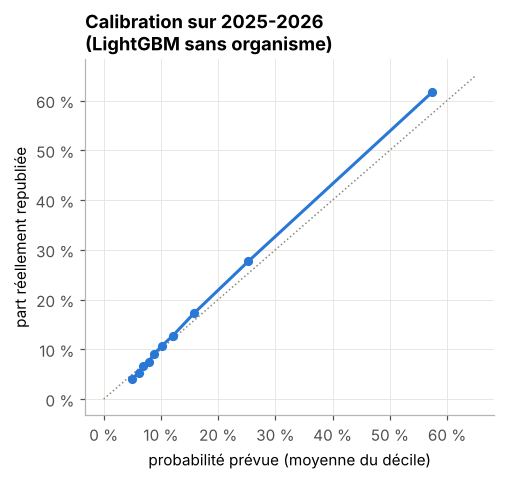

In [6]:
modele, COLS = modeles[RETENUE]
p_test = modele.predict(X_test[COLS])
rang = np.argsort(np.argsort(p_test))
deciles = pl.DataFrame({"p": p_test, "y": y_test, "d": rang * 10 // len(p_test)})
cal = deciles.group_by("d").agg(prevu=pl.col("p").mean(), observe=pl.col("y").mean()).sort("prevu")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 0.65], [0, 0.65], color=g.GRIS, lw=1, ls=":")
ax.plot(cal["prevu"], cal["observe"], "-o", color=g.PALETTE[0], ms=5)
ax.xaxis.set_major_formatter(POURCENT)
ax.yaxis.set_major_formatter(POURCENT)
ax.set_xlabel("probabilité prévue (moyenne du décile)")
ax.set_ylabel("part réellement republiée")
ax.set_title(f"Calibration sur 2025-2026\n(LightGBM {RETENUE})")
g.enregistrer(fig, "20_calibration_republication")
cal

Sur la validation 2024, l'historique apporte le plus (AUC 0,697 sans lui, 0,736 avec) et l'organisme presque rien
(0,739) : la variante sans organisme est retenue. Sur le test 2025-2026, elle atteint une AUC de 0,78 ; son décile le
plus à risque contient 62 % d'annonces republiées, contre 16 % en moyenne.

Une règle simple fait presque aussi bien : le taux de republication du couple métier × historique atteint 0,76 d'AUC et
60 % dans son décile haut. Le modèle ajoute 0,02 d'AUC et 2 points ; l'essentiel du signal tient en deux questions :
quel métier, et ce poste a-t-il déjà été publié dans l'année ? Le taux du métier seul (0,67) ou du couple métier ×
département (0,68) en sont loin.

La calibration est correcte au milieu mais le modèle sous-estime le haut (57 % prévus, 62 % observés dans le dernier
décile) et surestime le bas : la part de republications a monté entre la période d'apprentissage et celle du test
(16,3 % sur le test), et le modèle ne peut pas le savoir.

## 3. Ce qui pèse dans la prévision

Les valeurs SHAP décomposent chaque prévision en contributions des variables (en log-cote : + 0,1 multiplie à peu près
la cote de republication par 1,1). On les calcule sur 100 000 annonces de la période de test. Leur moyenne par modalité
dit combien une caractéristique pousse la prévision, en moyenne, au-dessus ou en dessous de la prévision moyenne. Ce
n'est pas un effet causal, ni tout à fait un effet « toutes choses égales par ailleurs » : quand des variables sont
liées (catégorie, management, expérience, métier), le modèle partage leur influence entre elles. Les champs facultatifs
(télétravail, management, expérience) sont souvent vides : la modalité « non renseigné » est montrée à part.

variable,shap_moyen_abs
str,f64
"""publications_an""",0.448572
"""metier""",0.229611
"""departement""",0.142458
"""deja_republiee""",0.071578
"""categorie""",0.048491
"""management""",0.04528
"""versant""",0.021889
"""teletravail""",0.016098
"""postes_annonce""",0.01374


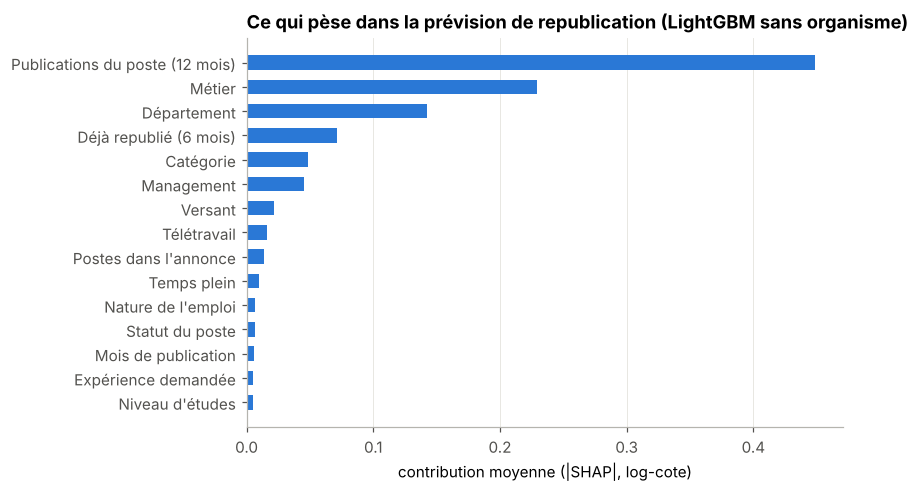

In [7]:
rng = np.random.default_rng(0)
idx = rng.choice(len(X_test), 100_000, replace=False)
Xs = X_test[COLS].iloc[idx]
contrib = modele.predict(Xs, pred_contrib=True)[:, :-1]
importance = pl.DataFrame({"variable": COLS, "shap_moyen_abs": np.abs(contrib).mean(axis=0)}).sort("shap_moyen_abs", descending=True)
NOMS = {"metier": "Métier", "departement": "Département", "publications_an": "Publications du poste (12 mois)",
        "deja_republiee": "Déjà republié (6 mois)", "mois": "Mois de publication", "categorie": "Catégorie",
        "versant": "Versant", "nature_emploi": "Nature de l'emploi", "statut_poste": "Statut du poste",
        "experience": "Expérience demandée", "teletravail": "Télétravail", "management": "Management",
        "temps_plein": "Temps plein", "niveau_etudes": "Niveau d'études", "postes_annonce": "Postes dans l'annonce",
        "organisme": "Organisme"}
fig, ax = plt.subplots(figsize=(7, 4.6))
imp = importance.reverse()
ax.barh([NOMS[v] for v in imp["variable"]], imp["shap_moyen_abs"], color=g.PALETTE[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("contribution moyenne (|SHAP|, log-cote)")
ax.set_title(f"Ce qui pèse dans la prévision de republication (LightGBM {RETENUE})")
g.enregistrer(fig, "21_importance_republication")
importance

categorie [('C', 0.059, 40745), ('B', -0.009, 24019), ('A', -0.05, 31345), ('A+', -0.099, 2184), ('non renseigné', -0.099, 1707)]
experience [('Débutant', 0.012, 7134), ('non renseigné', 0.002, 69757), ('Expert', -0.005, 2184), ('Confirmé', -0.012, 20925)]
management [('non renseigné', 0.035, 49092), ('sans management', 0.014, 39854), ('avec management', -0.194, 11054)]
nature_emploi [('titulaires et contractuels', 0.004, 84183), ('contractuels seulement', -0.021, 13994), ('fonctionnaires et lauréats', -0.027, 1596)]
statut_poste [('non renseigné', 0.044, 4304), ("Susceptible d'être vacant", 0.027, 5051), ('Vacant', -0.002, 90645)]
teletravail [('télétravail exclu', 0.027, 29901), ('non renseigné', -0.002, 51893), ('télétravail possible', -0.024, 18206)]
temps_plein [('temps partiel', 0.005, 12477), ('temps plein', 0.004, 78876), ('non renseigné', -0.048, 8647)]


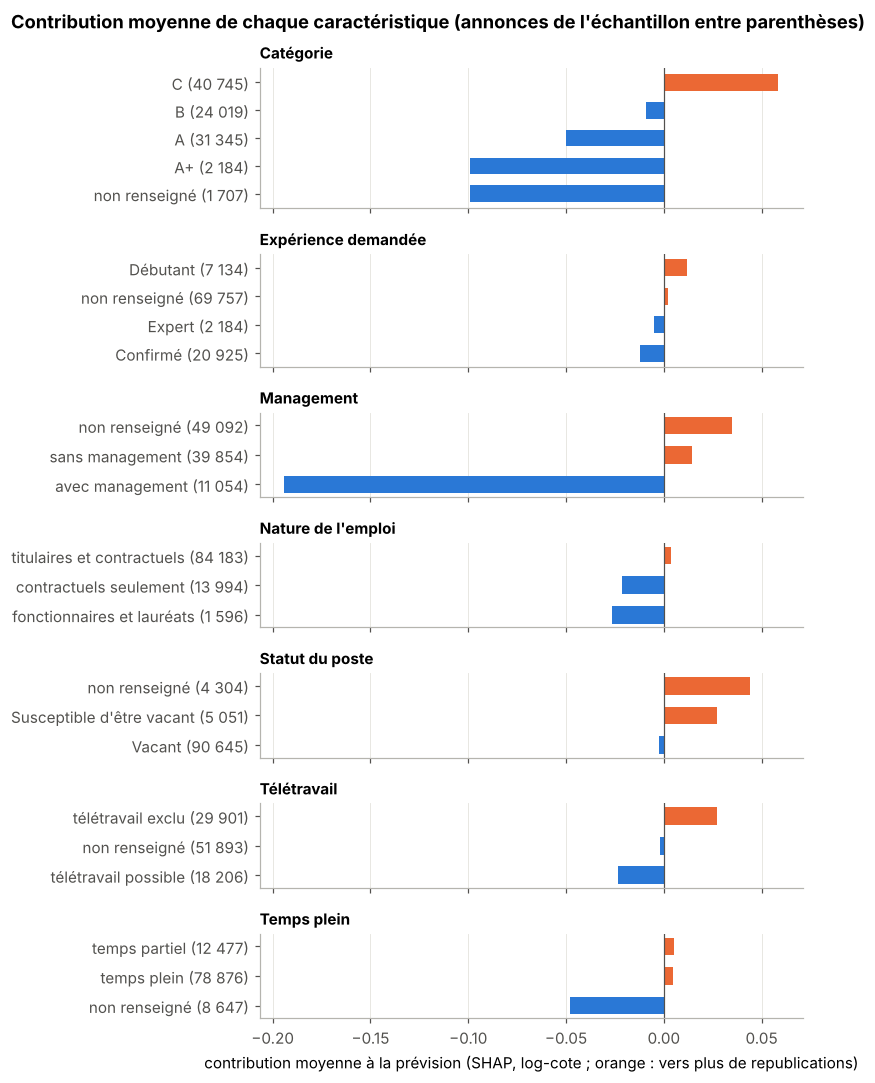

In [8]:
S = pl.DataFrame({c: contrib[:, i] for i, c in enumerate(COLS)})
V = pl.from_pandas(Xs.reset_index(drop=True).astype({c: str for c in rec.CATEGORIELLES if c in COLS}))
BINAIRES = {"teletravail": ("télétravail possible", "télétravail exclu"), "management": ("avec management", "sans management"),
            "temps_plein": ("temps plein", "temps partiel")}
COURTS = {"Emploi réservé aux fonctionnaires et lauréats d'un concours territorial": "fonctionnaires et lauréats",
          "Emploi ouvert aux titulaires et aux contractuels": "titulaires et contractuels",
          "Emploi ouvert uniquement aux contractuels": "contractuels seulement"}
def modalites(col):
    v = V[col]
    if col in BINAIRES:
        oui, non = BINAIRES[col]
        return v.map_elements(lambda x: oui if x == 1 else non if x == 0 else "non renseigné", return_dtype=pl.Utf8, skip_nulls=False)
    return v.cast(pl.Utf8).replace({"nan": None, "None": None}).fill_null("non renseigné").replace(COURTS)
def effet(col, min_n=300):
    return (pl.DataFrame({"modalite": modalites(col), "shap": S[col]}).group_by("modalite")
            .agg(shap=pl.col("shap").mean(), n=pl.len()).filter(pl.col("n") >= min_n).sort("shap", descending=True))
blocs = ["categorie", "experience", "management", "nature_emploi", "statut_poste", "teletravail", "temps_plein"]
effets = {c: effet(c) for c in blocs}
fig, axes = plt.subplots(len(blocs), 1, figsize=(7.5, 10), sharex=True,
                         gridspec_kw={"height_ratios": [max(2, effets[c].height) for c in blocs]})
for ax, col in zip(axes, blocs):
    e = effets[col].reverse()
    ax.barh([f"{m} ({n:,})".replace(",", " ") for m, n in zip(e["modalite"], e["n"])], e["shap"],
            color=[g.PALETTE[1] if v > 0 else g.PALETTE[0] for v in e["shap"]], height=0.6)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(NOMS[col], fontsize=10, loc="left")
    ax.grid(axis="y", visible=False)
axes[-1].set_xlabel("contribution moyenne à la prévision (SHAP, log-cote ; orange : vers plus de republications)")
fig.suptitle("Contribution moyenne de chaque caractéristique (annonces de l'échantillon entre parenthèses)",
             x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
g.enregistrer(fig, "22_effets_republication")
for col in blocs:
    print(col, [(m, round(v, 3), n) for m, v, n in effets[col].iter_rows()])

Métiers, contribution la plus forte : [('Auxiliaire de vie - Aide à domicile', 0.72), ("Assistante / Assistant d'éducation de la petite enfance", 0.64), ('Aide-soignante / Aide-soignant', 0.63), ('Travailleuse sociale / Travailleur social', 0.48), ('Agente locale / Agent local de tranquillité publique', 0.48), ('Animatrice éducative / Animateur éducatif accompagnement périscolaire', 0.47), ('Animatrice / Animateur enfance-jeunesse', 0.46), ('Assistante / Assistant de service social', 0.46)]
Métiers, contribution la plus faible : [("Chargée / Chargé d'animation auprès des publics", -0.42), ('Chargée / Chargé de bibliothèque', -0.44), ('Technicienne / Technicien du spectacle', -0.48), ('Chargée / Chargé de production culturelle', -0.55), ('Chargée / Chargé de politique environnementale', -0.58)]


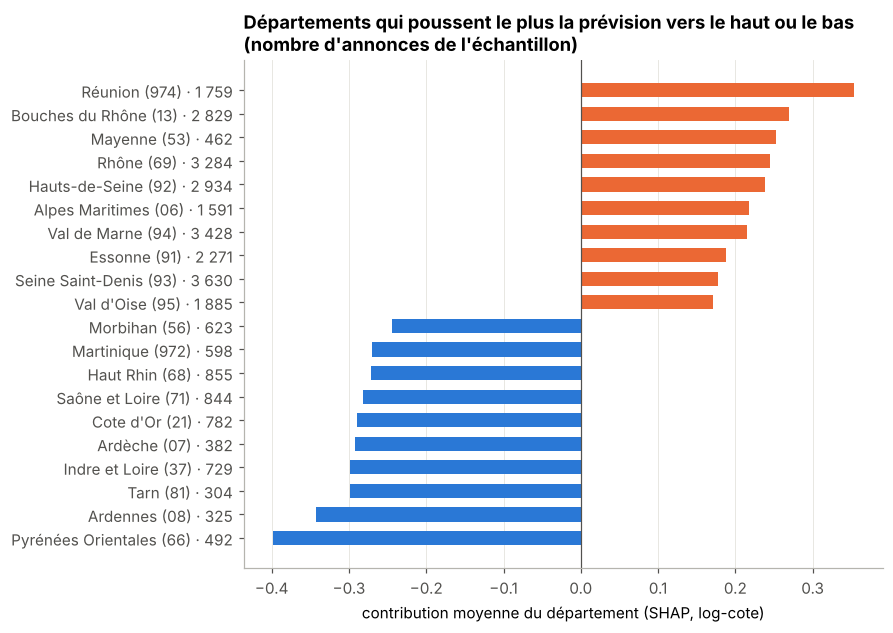

In [9]:
dep = effet("departement", min_n=300)
noms_dep = dict(offres.select("departement", "departement_nom").drop_nulls().unique("departement").iter_rows())
extremes = pl.concat([dep.head(10), dep.tail(10)]).with_columns(nom=pl.col("modalite").replace_strict(noms_dep, default=pl.col("modalite")))
fig, ax = plt.subplots(figsize=(7.5, 6))
e = extremes.reverse()
ax.barh([f"{nom} ({c}) · {n:,}".replace(",", " ") for nom, c, n in zip(e["nom"], e["modalite"], e["n"])], e["shap"],
        color=[g.PALETTE[1] if v > 0 else g.PALETTE[0] for v in e["shap"]], height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("contribution moyenne du département (SHAP, log-cote)")
ax.set_title("Départements qui poussent le plus la prévision vers le haut ou le bas\n(nombre d'annonces de l'échantillon)")
g.enregistrer(fig, "23_departements_republication")
mt = effet("metier", min_n=300)
print("Métiers, contribution la plus forte :", [(m, round(v, 2)) for m, v, _ in mt.head(8).iter_rows()])
print("Métiers, contribution la plus faible :", [(m, round(v, 2)) for m, v, _ in mt.tail(5).iter_rows()])

L'historique du poste, le métier et le département pèsent de loin le plus ; viennent ensuite la catégorie et le
management, le reste compte peu. En moyenne :
- les postes **avec management** tirent nettement la prévision vers le bas (- 0,19 en log-cote, une cote réduite
  d'environ 18 %), comme la **catégorie A+** (- 0,10) ; la **catégorie C** la tire vers le haut (+ 0,06) ;
- le **télétravail** possible va avec un peu moins de republications que le télétravail exclu, l'ouverture aux seuls
  contractuels aussi ; ces contributions restent faibles (moins de 0,03), comme celles de l'expérience demandée ;
- les champs non renseignés ont leurs propres contributions, toutes inférieures à 0,05 en valeur absolue.

Côté métiers, les contributions les plus fortes vont à l'aide à domicile, la petite enfance, les aides-soignants, le
travail social, la tranquillité publique et l'animation ; les plus faibles à la culture, aux bibliothèques et à
l'environnement. Les directions d'établissement d'éducation, en tête des taux bruts, n'y figurent pas : le modèle
attribue leur taux à l'historique de leurs postes, souvent republiés. Les départements qui poussent le plus la
prévision vers le haut ou le bas sont dans la figure 23 ; ces écarts mêlent tension réelle et habitudes de publication
des employeurs locaux, que le modèle ne sait pas séparer.

## 4. Les compétences demandées

Le texte de compétences n'existe que pour une annonce sur vingt, presque toutes à l'État ou à l'hôpital, et sa présence
dépend du format de publication des employeurs (il devient rare en 2026) : il n'entre pas dans le modèle. On regarde à
part, sur les annonces de 2025 qui en ont un, si certaines compétences vont avec plus de republications **que ce que
prévoit le modèle complet** pour ce poste (métier, lieu, organisme, conditions) : l'écart moyen entre republication
observée et prévue, par compétence citée dans au moins 150 de ces annonces. Comme les annonces d'un même employeur se
ressemblent, l'intervalle à 95 % est calculé par grappes d'organismes, et on affiche le nombre d'organismes et la part du
premier d'entre eux.

14,525 annonces de 2025 avec des compétences ; écart moyen observé - prévu : -0.017 (retiré)
90 compétences testées, 15 dont l'intervalle exclut 0, citées par au moins 5 organismes dont aucun ne pèse plus de la moitié


forme,n,G,premier,part_premier,ecart,marge,net
str,u32,u32,str,f64,f64,f64,bool
"""estimation des couts d une operation d infrastructure""",200,8,"""Service infrastructure de la défense (SID)""",0.91,0.10248,0.023785,false
"""regles de realisation d une operation d infra""",191,8,"""Service infrastructure de la défense (SID)""",0.905759,0.087659,0.022839,false
"""regles et procedures d execution de la depense""",219,17,"""Service du commissariat des armées (SCA)""",0.283105,0.08383,0.046674,true
"""discipline""",152,13,"""Armée de terre""",0.427632,0.077476,0.112316,false
"""regles du marche public de travaux""",346,8,"""Service infrastructure de la défense (SID)""",0.950867,0.072075,0.015226,false
"""principes et regles necessaires a la bonne execution financiere des marches publ…",186,16,"""Service infrastructure de la défense (SID)""",0.306452,0.069886,0.032149,true
"""reglementation et jurisprudence de la commande publique""",499,21,"""Service du commissariat des armées (SCA)""",0.306613,0.069059,0.033854,true
"""service national""",154,2,"""Direction du service national et de la jeunesse (DSNJ)""",0.974026,0.047071,0.007358,false
"""conduite controle reception des travaux""",166,9,"""Service infrastructure de la défense (SID)""",0.909639,0.046807,0.02046,false


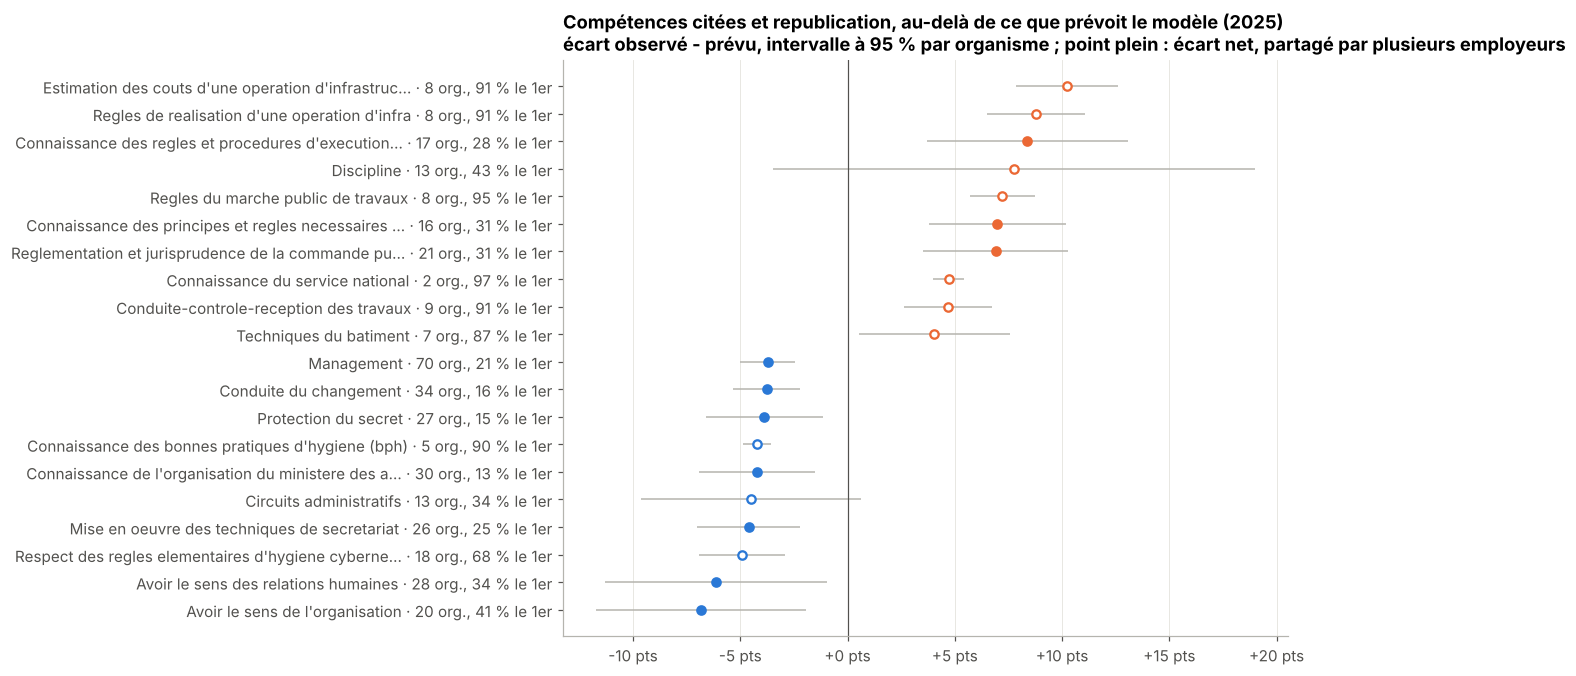

In [10]:
items = pl.read_parquet(donnees.chemin("competences_items.parquet")).unique(["annonce_id", "forme"])
complet, cols_complet = modeles["complet"]
t25 = test.with_columns(ecart=pl.Series(y_test - complet.predict(X_test[cols_complet]))).filter(pl.col("annee") == 2025)
residu = t25.filter(pl.col("annonce_id").is_in(items["annonce_id"].unique().implode())).select("annonce_id", "organisme", "ecart")
# Le modèle se trompe en moyenne un peu sur les annonces avec texte : on centre l'écart sur ces annonces
print(f"{residu.height:,} annonces de 2025 avec des compétences ; écart moyen observé - prévu : {residu['ecart'].mean():+.3f} (retiré)")
residu = residu.with_columns(ecart=pl.col("ecart") - pl.col("ecart").mean())
avec = residu.join(items, on="annonce_id")
grappes = (avec.with_columns(m=pl.col("ecart").mean().over("forme"))
           .group_by("forme", "organisme").agg(s=(pl.col("ecart") - pl.col("m")).sum(), k=pl.len()))
robuste = (grappes.group_by("forme").agg(v=(pl.col("s") ** 2).sum(), G=pl.len(),
                                         part_premier=pl.col("k").max() / pl.col("k").sum(),
                                         premier=pl.col("organisme").sort_by("k", descending=True).first()))
par_forme = (avec.group_by("forme").agg(n=pl.len(), ecart=pl.col("ecart").mean()).filter(pl.col("n") >= 150)
             .join(robuste, on="forme")
             .with_columns(marge=1.96 * (pl.col("v") * pl.col("G") / (pl.col("G") - 1).clip(lower_bound=1)).sqrt() / pl.col("n"))
             # Une compétence citée surtout par un seul employeur ne dit rien de la compétence : on ne la retient pas
             .with_columns(net=(pl.col("ecart").abs() > pl.col("marge")) & (pl.col("G") >= 5) & (pl.col("part_premier") <= 0.5))
             .sort("ecart", descending=True))
print(f"{par_forme.height} compétences testées, {par_forme['net'].sum()} dont l'intervalle exclut 0, citées par au moins "
      f"5 organismes dont aucun ne pèse plus de la moitié")
graphies = comp.items_des_offres(offres).group_by("forme", "item").len()
majoritaire = graphies.sort(["len", "item"], descending=[True, False]).group_by("forme", maintain_order=True).first()
accent = (graphies.filter(pl.col("item").str.contains(r"[éèêàâùûôîç]")).sort(["len", "item"], descending=[True, False])
          .group_by("forme", maintain_order=True).first())
LIB = dict(majoritaire.join(accent, on="forme", how="left", suffix="_a")
           .select("forme", pl.when(pl.col("len_a") >= 0.2 * pl.col("len")).then("item_a").otherwise("item")).iter_rows())
def lib(f, n=58):
    t = LIB.get(f, f)
    t = t.capitalize() if t.isupper() else t[0].upper() + t[1:]
    return t if len(t) <= n else t[: n - 1] + "…"
ext = pl.concat([par_forme.head(10), par_forme.tail(10)]).reverse()
fig, ax = plt.subplots(figsize=(8.5, 6.8))
ax.errorbar(ext["ecart"], range(ext.height), xerr=ext["marge"], fmt="none", ecolor="#b5b4ae", lw=1)
for i, (v, net) in enumerate(zip(ext["ecart"], ext["net"])):
    c = g.PALETTE[1] if v > 0 else g.PALETTE[0]
    ax.scatter([v], [i], s=30, zorder=3, color=c if net else "white", edgecolors=c, linewidths=1.5)
ax.set_yticks(range(ext.height), [f"{lib(f, 50)} · {k} org., {p:.0%} le 1er".replace("%", " %")
                                   for f, k, p in zip(ext["forme"], ext["G"], ext["part_premier"])])
ax.axvline(0, color="#52514e", lw=0.8)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.grid(axis="y", visible=False)
ax.set_title("Compétences citées et republication, au-delà de ce que prévoit le modèle (2025)\n"
             "écart observé - prévu, intervalle à 95 % par organisme ; point plein : écart net, partagé par plusieurs employeurs")
g.enregistrer(fig, "24_competences_republication")
pl.concat([par_forme.head(10), par_forme.tail(10)]).select("forme", "n", "G", "premier", "part_premier", "ecart", "marge", "net")

Les plus gros écarts sont trompeurs : les compétences d'ingénierie d'infrastructure (estimation des coûts d'une
opération, réalisation d'opérations, marché public de travaux) sont citées à 90 % par un seul employeur, le Service
d'infrastructure de la défense. Leur écart (+ 7 à + 10 points) dit que ce service a plus republié en 2025 que le modèle
ne l'attendait, pas que ces compétences sont rares.

Parmi les compétences partagées par plusieurs employeurs, l'exécution de la dépense et la commande publique vont avec
plus de republications que prévu (+ 7 à + 8 points), le management, la conduite du changement, la protection du secret,
le secrétariat et des savoir-être du secrétariat des juridictions avec moins (- 4 à - 7 points). Ces écarts portent sur
une seule année et sur des annonces de l'État surtout ; ce sont des pistes, pas des résultats établis.

## À retenir

- Une annonce sur sept est **republiée** dans les six mois, et la part monte (12,7 % en 2022, 16,2 % en 2025).
- Les métiers de l'aide à domicile, de la petite enfance, du travail social et du soin sont les plus republiés (27 à
  39 %) ; les directions culturelles et des systèmes d'information, la communication et les cadres dirigeants le moins
  (moins de 5 %).
- Le modèle LightGBM prévoit la republication avec une AUC de 0,78 sur des années qu'il n'a pas vues, mais une règle
  simple (métier × publications du poste dans l'année) fait presque aussi bien (0,76) : le métier et l'historique du
  poste portent l'essentiel du signal.
- Les postes avec management et de catégorie A+ vont avec moins de republications, ceux de catégorie C avec plus.
- Les compétences n'apportent que des pistes : les écarts les plus forts tiennent à un seul employeur.